Red fractional order: 0.566953
Green fractional order: 0.551412


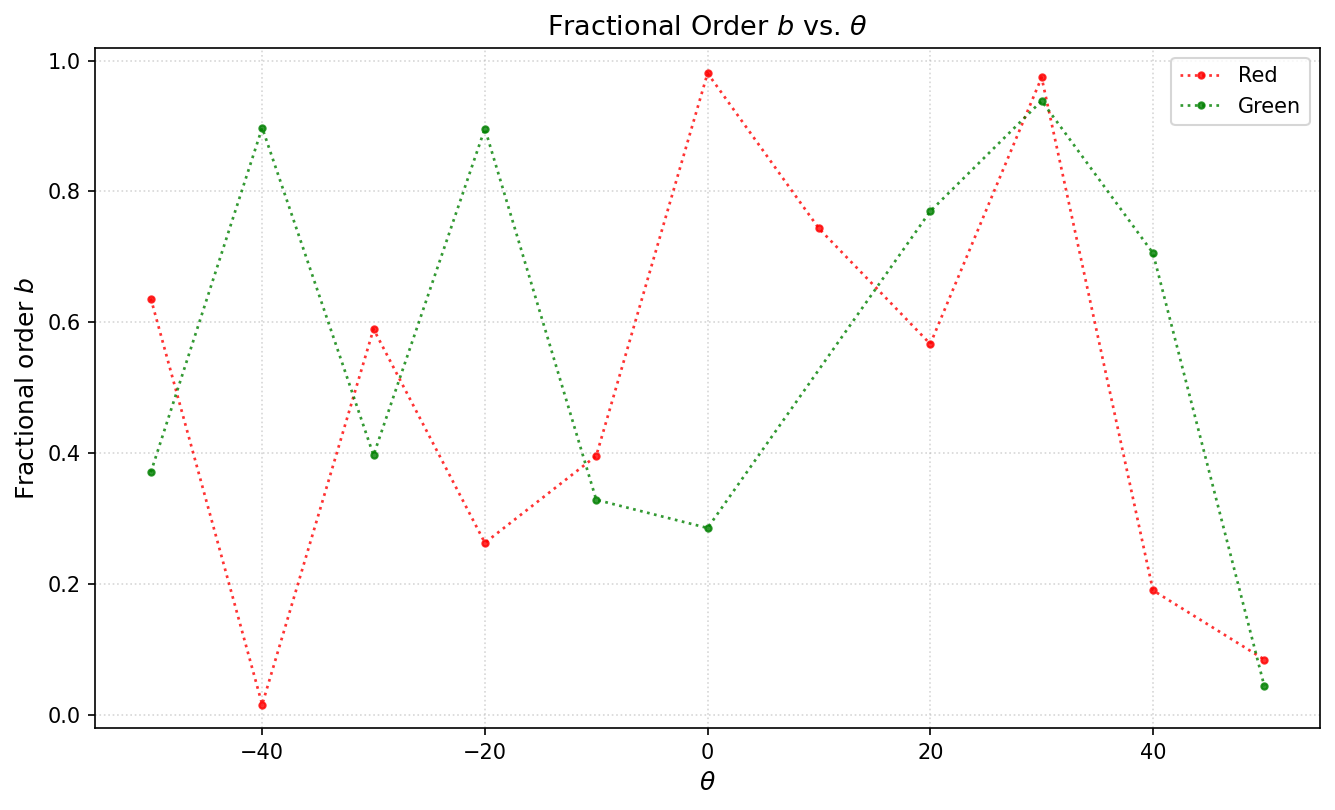


Dual-Wavelength Least-Squares Results
-------------------------------------------------------
Red laser:   693.0 nm | N = 452 | L = 156.814449 µm
Green laser: 532.0 nm | N = 589 | L = 156.820676 µm
Optimal thickness: 156.817536 µm
Difference between lasers: 0.006227 µm
Normalized combined error: 4.122051e-04


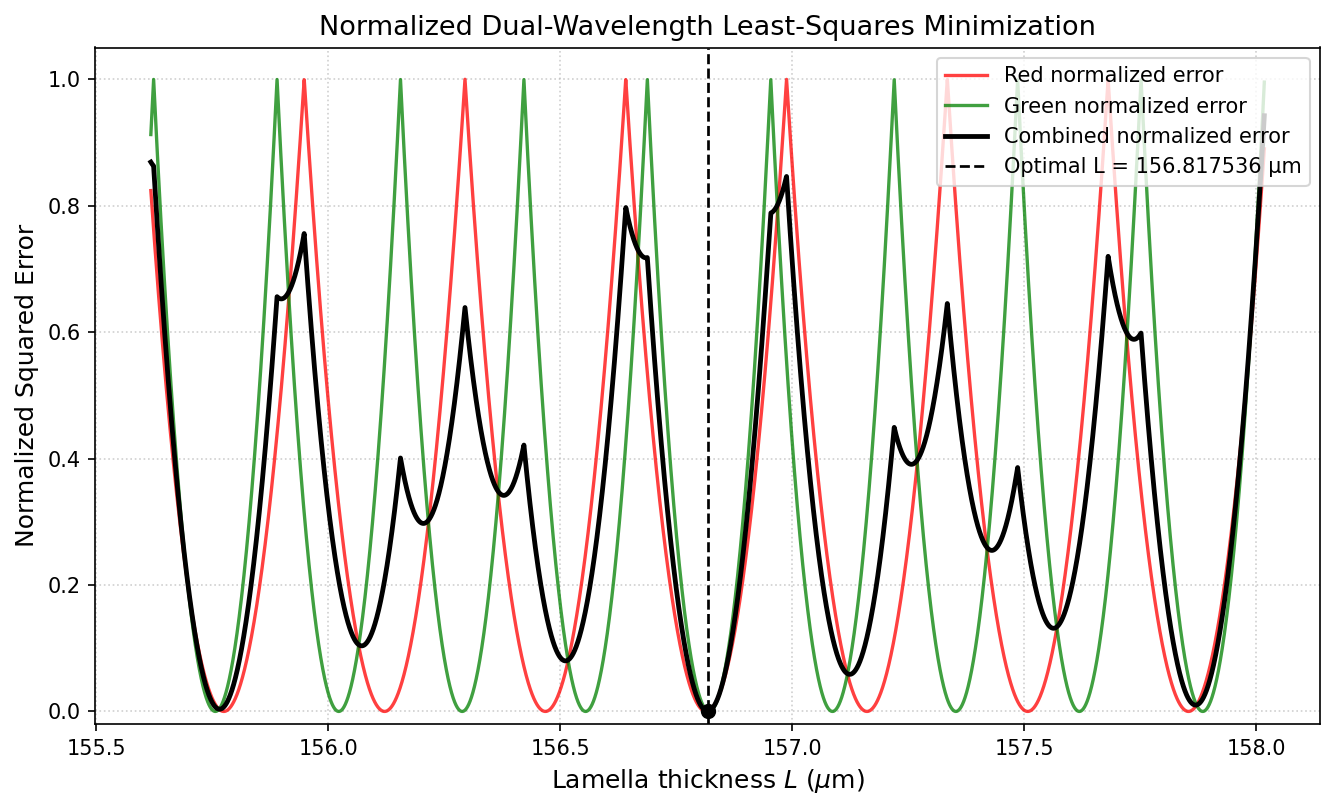

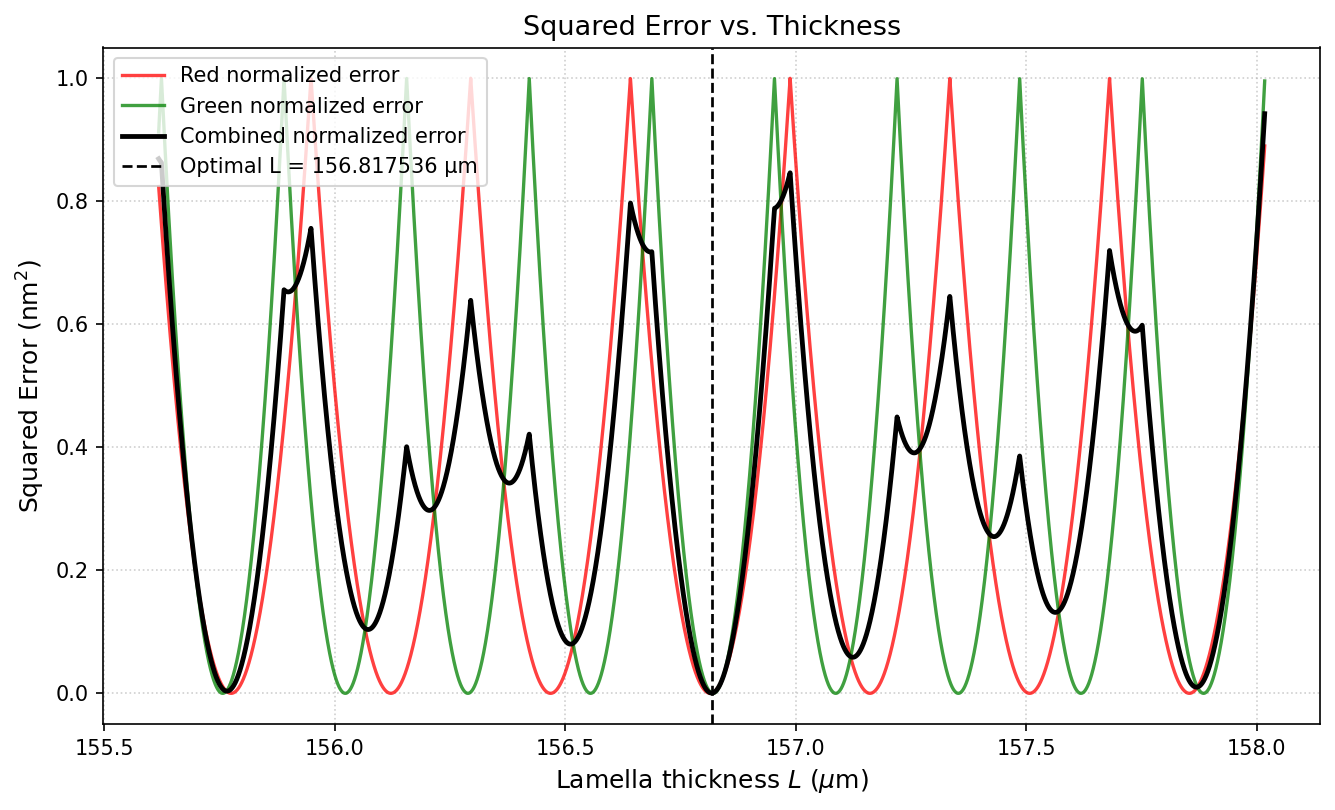


Results saved to: C:\Users\Lenovo\Downloads\Book1_Corrected_Results.xlsx
Figures saved to: C:\Users\Lenovo\Downloads\results


In [33]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# File paths
folder = r"C:\Users\Lenovo\Downloads"
input_file = os.path.join(folder, "ziba_with_new_b.xlsx")
output_file = os.path.join(folder, "Book1_Corrected_Results.xlsx")
output_dir = os.path.join(folder, "results")
os.makedirs(output_dir, exist_ok=True)

WAVELENGTHS = {"Red": 693.0, "Green": 532.0}
plot_colors = {"Red": "red", "Green": "green"}

# Load data
df = pd.read_excel(input_file)
df.columns = [str(c).strip() for c in df.columns]

required = ["Image", "Period (i)", "Shift (Δi)", "color", "theta"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}\nAvailable columns: {df.columns.tolist()}")

df["Period (i)"] = pd.to_numeric(df["Period (i)"], errors="coerce")
df["Shift (Δi)"] = pd.to_numeric(df["Shift (Δi)"], errors="coerce")
df["theta"] = pd.to_numeric(df["theta"], errors="coerce")
df["color"] = df["color"].astype(str).str.strip().str.capitalize()
df = df.dropna(subset=["Period (i)", "Shift (Δi)", "color", "theta"]).copy()
df = df[df["Period (i)"] > 0].copy()
df["Wavelength_nm"] = df["color"].map(WAVELENGTHS)
df = df.dropna(subset=["Wavelength_nm"]).copy()
df["Raw_Order"] = df["Shift (Δi)"] / df["Period (i)"]
df["Fractional_b"] = np.mod(df["Raw_Order"], 1.0)

if df.empty:
    raise ValueError("No valid measurements were found.")

# Fractional order for each laser
b_dict = {color: df.loc[df["color"] == color, "Fractional_b"].median() for color in WAVELENGTHS}
if any(pd.isna(value) for value in b_dict.values()):
    raise ValueError("Check that both Red and Green measurements are present.")

b_R, b_G = b_dict["Red"], b_dict["Green"]
lambda_R, lambda_G = WAVELENGTHS["Red"], WAVELENGTHS["Green"]

print(f"Red fractional order: {b_R:.6f}")
print(f"Green fractional order: {b_G:.6f}")

# Plot b against theta
plt.figure(figsize=(9, 5.5), dpi=150)
for color in WAVELENGTHS:
    data = df[df["color"] == color].sort_values("theta")
    plt.plot(data["theta"], data["Fractional_b"], color=plot_colors[color], linestyle=":", linewidth=1.3, alpha=0.8, marker="o", markersize=3, label=color)
plt.xlabel(r"$\theta$", fontsize=12)
plt.ylabel(r"Fractional order $b$", fontsize=12)
plt.title(r"Fractional Order $b$ vs. $\theta$", fontsize=13)
plt.ylim(-0.02, 1.02)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Fractional_b_vs_theta.png"), dpi=300, bbox_inches="tight")
plt.show()

# Search for the optimal thickness
L_target_um, search_width_um, n_points = 155.0, 5.0, 50000
L_test_um = np.linspace(L_target_um - search_width_um, L_target_um + search_width_um, n_points)
L_test_nm = L_test_um * 1000.0

N_R = np.round(2 * L_test_nm / lambda_R - b_R)
N_G = np.round(2 * L_test_nm / lambda_G - b_G)
error_R = (2 * L_test_nm - (N_R + b_R) * lambda_R) ** 2
error_G = (2 * L_test_nm - (N_G + b_G) * lambda_G) ** 2
error_total = error_R + error_G

best_idx = np.argmin(error_total)
best_L_um = L_test_um[best_idx]
best_N_R, best_N_G = int(N_R[best_idx]), int(N_G[best_idx])
L_R_indep = (best_N_R + b_R) * lambda_R / 2000.0
L_G_indep = (best_N_G + b_G) * lambda_G / 2000.0

norm_error_R = error_R / np.max(error_R) if np.max(error_R) > 0 else np.zeros_like(error_R)
norm_error_G = error_G / np.max(error_G) if np.max(error_G) > 0 else np.zeros_like(error_G)
norm_error_total = error_total / np.max(error_total) if np.max(error_total) > 0 else np.zeros_like(error_total)

print("\nDual-Wavelength Least-Squares Results")
print("-" * 55)
print(f"Red laser:   {lambda_R:.1f} nm | N = {best_N_R} | L = {L_R_indep:.6f} µm")
print(f"Green laser: {lambda_G:.1f} nm | N = {best_N_G} | L = {L_G_indep:.6f} µm")
print(f"Optimal thickness: {best_L_um:.6f} µm")
print(f"Difference between lasers: {abs(L_R_indep - L_G_indep):.6f} µm")
print(f"Normalized combined error: {norm_error_total[best_idx]:.6e}")

# Plot normalized errors near the minimum
zoom = (L_test_um >= best_L_um - 1.2) & (L_test_um <= best_L_um + 1.2)
plt.figure(figsize=(9, 5.5), dpi=150)
plt.plot(L_test_um[zoom], norm_error_R[zoom], color="red", linewidth=1.6, alpha=0.75, label="Red normalized error")
plt.plot(L_test_um[zoom], norm_error_G[zoom], color="green", linewidth=1.6, alpha=0.75, label="Green normalized error")
plt.plot(L_test_um[zoom], norm_error_total[zoom], color="black", linewidth=2.3, label="Combined normalized error")
plt.axvline(best_L_um, color="black", linestyle="--", linewidth=1.3, label=f"Optimal L = {best_L_um:.6f} µm")
plt.scatter(best_L_um, norm_error_total[best_idx], color="black", s=40, zorder=5)
plt.xlabel(r"Lamella thickness $L$ ($\mu$m)", fontsize=12)
plt.ylabel("Normalized Squared Error", fontsize=12)
plt.title("Normalized Dual-Wavelength Least-Squares Minimization", fontsize=13)
plt.ylim(-0.02, 1.05)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Normalized_Minimization.png"), dpi=300, bbox_inches="tight")
plt.show()

# Plot squared errors
plt.figure(figsize=(9, 5.5), dpi=150)
plt.plot(L_test_um[zoom], norm_error_R[zoom], color="red", linewidth=1.6, alpha=0.75, label="Red normalized error")
plt.plot(L_test_um[zoom], norm_error_G[zoom], color="green", linewidth=1.6, alpha=0.75, label="Green normalized error")
plt.plot(L_test_um[zoom], norm_error_total[zoom], color="black", linewidth=2.3, label="Combined normalized error")
plt.axvline(best_L_um, color="black", linestyle="--", linewidth=1.3, label=f"Optimal L = {best_L_um:.6f} µm")
plt.xlabel(r"Lamella thickness $L$ ($\mu$m)", fontsize=12)
plt.ylabel(r"Squared Error (nm$^2$)", fontsize=12)
plt.title("Squared Error vs. Thickness", fontsize=13)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Squared_Error_vs_Thickness.png"), dpi=300, bbox_inches="tight")
plt.show()

# Export results
statistics_df = df.groupby("color").agg(Number_of_Measurements=("Fractional_b", "count"), Mean_b=("Fractional_b", "mean"), Median_b=("Fractional_b", "median"), Std_b=("Fractional_b", "std"), Mean_theta=("theta", "mean"), Wavelength_nm=("Wavelength_nm", "first")).reset_index()

laser_results_df = pd.DataFrame([
    {"Color": "Red", "Wavelength_nm": lambda_R, "Median_b": b_R, "Integer_Order_N": best_N_R, "Independent_Thickness_um": L_R_indep},
    {"Color": "Green", "Wavelength_nm": lambda_G, "Median_b": b_G, "Integer_Order_N": best_N_G, "Independent_Thickness_um": L_G_indep}
])

summary_df = pd.DataFrame([{
    "Optimal_Combined_Thickness_um": best_L_um,
    "Red_Thickness_um": L_R_indep,
    "Green_Thickness_um": L_G_indep,
    "Difference_Between_Lasers_um": abs(L_R_indep - L_G_indep),
    "Minimum_Combined_Squared_Error_nm2": error_total[best_idx],
    "Normalized_Combined_Error": norm_error_total[best_idx]
}])

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Processed_Data", index=False)
    statistics_df.to_excel(writer, sheet_name="Fractional_Order", index=False)
    laser_results_df.to_excel(writer, sheet_name="Laser_Results", index=False)
    summary_df.to_excel(writer, sheet_name="Final_Results", index=False)

print(f"\nResults saved to: {output_file}")
print(f"Figures saved to: {output_dir}")